# Why is historical TCAV nearly binary? (roadmap Work 2)

Almost every historical TCAV value is exactly 0 or 1. Two accounts can explain this:

- **(a) concentrated data:** the patients sit in a small region of embedding space where the frozen head's gradient barely changes direction.
- **(b) near-linear head:** the head's gradient points the same way wherever the input is.

This notebook runs handoff tests 1-4 on the historical frozen system: the archive embeddings and gradients, the frozen head, the November CAV fits and the patient-table groups of the same builds.

TCAV of one CAV fit in a group = share of the group's rows whose death-probability gradient has a strictly positive dot product with the fit's unit direction.

## Settings

In [1]:
BUILDS = None          # None = every build of the patient table; a list such as [("r1", 2007)] for a quick check
DEVICE = "cuda"        # device of the frozen head and SAE encoder
RUN_NAME = "full"      # output subfolder

ESTIMATORS = ("all_negatives", "legacy")
HEADLINE_GROUPS = ("A", "R", "all")
TOP_AXES = 5                                 # handoff tests 2-4: top-5 principal axes
PROJECTION_AXES = tuple(range(1, 11))        # handoff test 3: k = 1..10
SCALES = (0.0, 0.25, 0.5, 1.0, 2.0, 4.0)     # handoff test 4: displacement grid
RANDOM_DIRECTIONS = 2000                     # Monte Carlo draws per family and build-year
SEED = 20261118
INTERIOR = (0.1, 0.9)                        # pipeline TCAV_ELIGIBILITY_CUTOFFS; endpoints shown separately
BATCH_ROWS = 512

In [2]:
import datetime
import hashlib
import json
import resource
import subprocess
import sys
import time
from pathlib import Path

CODE_ROOT = Path.home() / "SAE-TCAV"
sys.path.insert(0, str(CODE_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import concept_subgroup_drift_pilot as pilot
import tcav_geometry as geometry
from concept_study import loading, measures, paths

OUTPUT = paths.OUTPUT / "extensions" / "tcav_geometry" / RUN_NAME
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
YEARS, GROUPS = measures.YEARS, measures.GROUPS
started = datetime.datetime.now().isoformat(timespec="seconds")
timings, errors = {}, []
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()


def panel(variants):
    return "primary" if paths.PRIMARY_VARIANT in variants else "auxiliary"


def save_figure(figure, name):
    figure.savefig(FIGURES / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## Builds and concepts

Primary panel: builds that serve `last_3` (references 2007-2013). Auxiliary panel: builds that serve only `all_history`.

In [3]:
index = measures.load_index()
builds = [b for b in index["builds"] if BUILDS is None or (b["build"], b["reference"]) in BUILDS]
concepts = {(b["build"], b["reference"]): [c for c in index["concepts"]
                                          if (c["build"], c["reference"]) == (b["build"], b["reference"])]
            for b in builds}
pd.DataFrame([{"build": b["build"], "reference": b["reference"], "panel": panel(b["variants"]),
               "concepts": len(concepts[(b["build"], b["reference"])]),
               "primary concepts": sum(panel(c["variants"]) == "primary" for c in concepts[(b["build"], b["reference"])])}
              for b in builds])

,build,reference,panel,concepts,primary concepts
0,all_history,2008,primary,6,6
1,all_history,2009,primary,10,10
2,all_history,2010,auxiliary,8,0
3,all_history,2011,auxiliary,7,0
4,all_history,2012,auxiliary,11,0
5,all_history,2013,auxiliary,7,0
6,last_3,2010,primary,7,7
7,last_3,2011,primary,14,14
8,last_3,2012,primary,7,7
9,last_3,2013,primary,14,14


## Step 1 — Is this the same measurement?

Load each build's archive rows, keep the evaluation rows, and check they are the patient-table rows in the same order (patient, year and cached probability equal exactly). Then recompute every stored sensitivity as gradient · unit CAV, and every saved per-fit TCAV from those sensitivities.

In [4]:
step = time.time()
inputs = loading.open_inputs(DEVICE)
directions, _ = loading.load_cav_directions()
data = {}
for record in builds:
    key = (record["build"], record["reference"])
    roles = next(item["roles"] for item in inputs["inventory"] if (item["build"], item["reference"]) == key)
    base = loading.load_build(inputs, *key, roles)
    rows = np.flatnonzero(base["roles"] == "evaluation")
    table = measures.load_build(record)
    same_rows = (np.array_equal(base["patients"][rows].astype(str), table["patient_id"])
                 and np.array_equal(base["years"][rows], table["year"])
                 and np.array_equal(base["probabilities"][rows, 1].astype(np.float32), table["probability"]))
    if not same_rows:
        errors.append(f"{key}: evaluation rows differ from the patient table; build skipped")
        continue
    data[key] = {"panel": panel(record["variants"]), "year": table["year"], "scale": base["scale"],
                 "embeddings": base["embeddings"][rows], "gradients": base["gradients"][rows],
                 "probabilities": base["probabilities"][rows], "probability": table["probability"],
                 "continuation": base["continuation"]}
    print(f"{key}: {len(rows)} evaluation rows, same rows as the patient table")
timings["load"] = time.time() - step

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


('all_history', 2008): 2487 evaluation rows, same rows as the patient table
('all_history', 2009): 2212 evaluation rows, same rows as the patient table
('all_history', 2010): 1856 evaluation rows, same rows as the patient table
('all_history', 2011): 1601 evaluation rows, same rows as the patient table


('all_history', 2012): 1198 evaluation rows, same rows as the patient table
('all_history', 2013): 939 evaluation rows, same rows as the patient table
('last_3', 2010): 1856 evaluation rows, same rows as the patient table
('last_3', 2011): 1601 evaluation rows, same rows as the patient table
('last_3', 2012): 1198 evaluation rows, same rows as the patient table


('last_3', 2013): 939 evaluation rows, same rows as the patient table
('r1', 2007): 2713 evaluation rows, same rows as the patient table


In [5]:
step = time.time()
coverage, fits, concept_groups = [], [], {}
for key, build in data.items():
    for record in concepts[key]:
        concept, saved = measures.load_concept(record), measures.load_replicates(record)
        groups = measures.group_masks(concept)
        sizes = np.array([[(groups[:, g] & (build["year"] == year)).sum() for year in YEARS] for g in range(len(GROUPS))])
        concept_groups[record["concept"]] = (key, groups)
        for estimator in ESTIMATORS:
            row = {"build": key[0], "reference": key[1], "concept": record["concept"],
                   "panel": panel(record["variants"]), "estimator": estimator,
                   "cav_fits": record["cav_fits"][estimator], "valid_fits": 0,
                   "group_year_rows": int(sizes.sum()), "smallest_group_year_rows": int(sizes[sizes > 0].min())}
            matrix = directions.get((estimator, record["concept"]))
            if matrix is None or f"sensitivity_{estimator}" not in concept:
                coverage.append(row)
                continue
            stored = concept[f"sensitivity_{estimator}"]
            row.update(geometry.compare_sensitivities(build["gradients"], matrix, stored))
            tcav = geometry.per_fit_tcav(stored, groups, build["year"], YEARS)
            saved_tcav = saved[f"per_fit|{estimator}|tcav"]
            row["saved_shape_matches"] = tcav.shape == saved_tcav.shape
            if row["saved_shape_matches"]:
                row["max_tcav_difference"] = float(np.nanmax(np.abs(tcav - saved_tcav)))
                row["empty_cells_differ"] = int((np.isnan(tcav) != np.isnan(saved_tcav)).sum())
            row["empty_cells"] = int(np.isnan(tcav[..., 0]).sum())
            coverage.append(row)
            fits.append({"key": key, "concept": record["concept"], "panel": row["panel"], "estimator": estimator,
                         "directions": matrix[np.isfinite(matrix).all(axis=1)].astype(np.float64),
                         "groups": groups, "tcav": tcav})
coverage = pd.DataFrame(coverage)
coverage.to_csv(OUTPUT / "coverage.csv", index=False)
timings["reconcile"] = time.time() - step
coverage.groupby(["panel", "estimator"]).agg(
    concepts=("concept", "nunique"), with_fits=("valid_fits", lambda v: int((v > 0).sum())),
    group_year_rows=("group_year_rows", "sum"), max_sensitivity_difference=("max_abs_difference", "max"), sign_disagreements=("sign_disagreements", "sum"),
    max_tcav_difference=("max_tcav_difference", "max"), empty_cells_differ=("empty_cells_differ", "sum"))

concepts  with_fits  group_year_rows  \
panel     estimator                                             
auxiliary all_negatives        33         31           102557   
          legacy               33         31           102557   
primary   all_negatives        62         61           234132   
          legacy               62         61           234132   

                         max_sensitivity_difference  sign_disagreements  \
panel     estimator                                                       
auxiliary all_negatives                8.298919e-08                 0.0   
          legacy                       7.424760e-08                 0.0   
primary   all_negatives                9.886513e-08                 0.0   
          legacy                       8.723934e-08                 0.0   

                         max_tcav_difference  empty_cells_differ  
panel     estimator                                               
auxiliary all_negatives         2.926695e-08                 0.0  
          legacy                2.935484e-08                 0.0  
primary   all_negatives         2.971062e-08                 0.0  
          legacy                2.969991e-08                 0.0

## Step 2 — Does the frozen head reproduce every evaluation row?

The frozen loader replayed the head on only 8 rows. Before moving any embedding, replay probabilities and gradients on all evaluation rows and compare with the archive, using the pilot's own tolerances (probability rtol 1e-4 / atol 1e-5, gradient rtol 1e-3 / atol 1e-5). A build that fails gets no perturbation test (step 6).

In [6]:
print(next(iter(data.values()))["continuation"].head)
step = time.time()
replay = []
for key, build in data.items():
    start = time.time()
    try:
        probabilities = pilot.batched_death_probabilities(build["continuation"], build["embeddings"], BATCH_ROWS)
        gradients = pilot.batched_death_gradients(build["continuation"], build["embeddings"], BATCH_ROWS)
    except RuntimeError as error:
        errors.append(f"{key}: replay failed: {error}")
        build["replayed"] = False
        continue
    summary = geometry.replay_summary(probabilities, build["probabilities"], gradients, build["gradients"])
    build["replayed"] = summary["probability_within_tolerance"] and summary["gradient_within_tolerance"]
    replay.append({"build": key[0], "reference": key[1], "device": DEVICE, "seconds": time.time() - start, **summary})
replay = pd.DataFrame(replay)
replay.to_csv(OUTPUT / "replay.csv", index=False)
timings["replay"] = time.time() - step
replay

Sequential(
  (0): Linear(in_features=192, out_features=768, bias=True)
  (1): GELU(approximate='none')
  (2): Linear(in_features=768, out_features=10, bias=True)
)


,build,reference,device,seconds,rows,probability_max_abs_error,probability_max_relative_error,probability_within_tolerance,gradient_max_abs_error,gradient_max_relative_error,gradient_within_tolerance
0,all_history,2008,cuda,0.036532,2487,4.172325e-07,0.000003,True,4.470348e-08,4.391304,True
1,all_history,2009,cuda,0.017983,2212,4.172325e-07,0.000003,True,3.352761e-08,0.034955,True
2,all_history,2010,cuda,0.014428,1856,4.172325e-07,0.000003,True,4.470348e-08,0.014440,True
3,all_history,2011,cuda,0.013186,1601,4.768372e-07,0.000002,True,4.470348e-08,0.021173,True
4,all_history,2012,cuda,0.010488,1198,4.172325e-07,0.000002,True,4.470348e-08,0.150898,True
5,all_history,2013,cuda,0.007950,939,2.980232e-07,0.000002,True,3.352761e-08,0.012426,True
6,last_3,2010,cuda,0.015103,1856,4.172325e-07,0.000002,True,4.842877e-08,0.026799,True
7,last_3,2011,cuda,0.014371,1601,4.768372e-07,0.000003,True,4.656613e-08,0.064103,True
8,last_3,2012,cuda,0.010988,1198,3.576279e-07,0.000003,True,4.470348e-08,0.007417,True
9,last_3,2013,cuda,0.007790,939,4.172325e-07,0.000002,True,3.911555e-08,0.008742,True


## Step 3 — Test 1: do the gradients share one direction?

Per build-year, scale each gradient to unit length (the direction is the same on the probability and log-odds scales, because p(1 − p) > 0). Resultant length R = length of the mean unit gradient: 1 when every row points the same way, 0 when they cancel. Leading share = how much of the unit gradients lies on one line.

If all gradients shared one direction ū, every fit's TCAV would be exactly 1[ū · v > 0]. The table compares this prediction with the observed per-fit TCAV, using ū of all rows of the year and ū of the group's own rows.

In [7]:
step = time.time()
coherence = []
for key, build in data.items():
    build["log_odds"] = geometry.log_odds_gradients(build["gradients"], build["probability"])
    build["mean_direction"] = {}
    for year in YEARS:
        in_year = build["year"] == year
        if not in_year.any():
            continue
        summary = geometry.coherence(build["log_odds"][in_year])
        build["mean_direction"][year] = summary["mean_direction"]
        low, middle, high = np.quantile(summary["cosines"], [0.05, 0.5, 0.95])
        coherence.append({"build": key[0], "reference": key[1], "panel": build["panel"], "year": year,
                          "rows": int(in_year.sum()), "rows_used": summary["rows_used"],
                          "saturated_or_zero_rows": summary["rows_dropped"],
                          "resultant_length": summary["resultant_length"], "leading_share": summary["leading_share"],
                          "cosine_p05": low, "cosine_median": middle, "cosine_p95": high})
coherence = pd.DataFrame(coherence)
coherence.to_csv(OUTPUT / "coherence.csv", index=False)
coherence.groupby("panel")[["resultant_length", "leading_share", "cosine_p05", "cosine_median"]].describe().T

panel                   auxiliary    primary
resultant_length count  18.000000  42.000000
                 mean    0.983178   0.978299
                 std     0.003561   0.007878
                 min     0.976330   0.965944
                 25%     0.981615   0.972794
                 50%     0.982784   0.975682
                 75%     0.985325   0.984166
                 max     0.990814   0.994702
leading_share    count  18.000000  42.000000
                 mean    0.967120   0.958062
                 std     0.006772   0.014981
                 min     0.954216   0.934866
                 25%     0.963987   0.948176
                 50%     0.966385   0.953112
                 75%     0.971122   0.969252
                 max     0.981803   0.989494
cosine_p05       count  18.000000  42.000000
                 mean    0.934137   0.910324
                 std     0.024590   0.039055
                 min     0.889265   0.848552
                 25%     0.914683   0.879470
                 50%     0.935527   0.908217
                 75%     0.950218   0.950993
                 max     0.976416   0.979450
cosine_median    count  18.000000  42.000000
                 mean    0.989753   0.986974
                 std     0.002615   0.006848
                 min     0.985628   0.968889
                 25%     0.987430   0.982107
                 50%     0.989415   0.988691
                 75%     0.991846   0.991111
                 max     0.994103   0.996911

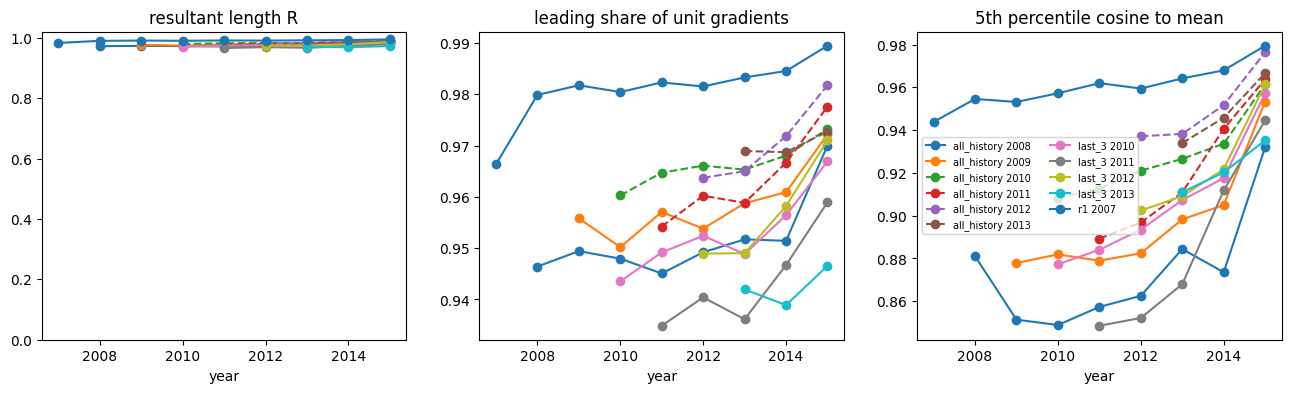

In [8]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4))
for (build, reference), rows in coherence.groupby(["build", "reference"]):
    style = "-" if rows["panel"].iloc[0] == "primary" else "--"
    for axis, column in zip(axes, ("resultant_length", "leading_share", "cosine_p05")):
        axis.plot(rows["year"], rows[column], style, marker="o", label=f"{build} {reference}")
for axis, title in zip(axes, ("resultant length R", "leading share of unit gradients", "5th percentile cosine to mean")):
    axis.set_title(title)
    axis.set_xlabel("year")
axes[0].set_ylim(0, 1.02)
axes[2].legend(fontsize=7, ncol=2)
save_figure(figure, "test1_coherence_by_year")

In [9]:
predictions = []
for fit in fits:
    build = data[fit["key"]]
    for g, group in enumerate(GROUPS):
        for y, year in enumerate(YEARS):
            rows = fit["groups"][:, g] & (build["year"] == year)
            if not rows.any():
                continue
            own = geometry.coherence(build["log_odds"][rows])
            shared = build["mean_direction"][year]
            predictions.append(pd.DataFrame({
                "build": fit["key"][0], "reference": fit["key"][1], "concept": fit["concept"], "panel": fit["panel"],
                "estimator": fit["estimator"], "group": group, "year": year, "rows": int(rows.sum()),
                "fit": np.arange(len(fit["directions"])), "observed_tcav": fit["tcav"][g, y],
                "predicted_all_rows": geometry.predicted_tcav(shared, fit["directions"]),
                "predicted_own_group": geometry.predicted_tcav(own["mean_direction"], fit["directions"]),
                "angle_all_rows": geometry.boundary_angle(shared, fit["directions"]),
                "angle_own_group": geometry.boundary_angle(own["mean_direction"], fit["directions"]),
                "group_resultant_length": own["resultant_length"]}))
predictions = pd.concat(predictions, ignore_index=True)
predictions["endpoint"] = predictions["observed_tcav"].isin([0.0, 1.0])
predictions["matches_all_rows"] = predictions["observed_tcav"] == predictions["predicted_all_rows"]
predictions["matches_own_group"] = predictions["observed_tcav"] == predictions["predicted_own_group"]
predictions["error_all_rows"] = (predictions["observed_tcav"] - predictions["predicted_all_rows"]).abs()
predictions.to_csv(OUTPUT / "per_fit_prediction.csv.gz", index=False)
timings["test1"] = time.time() - step
predictions[predictions["year"] <= paths.LAST_OUTCOME_YEAR].groupby(["panel", "estimator", "group"]).agg(
    fit_values=("observed_tcav", "size"), endpoint_share=("endpoint", "mean"),
    matches_all_rows=("matches_all_rows", "mean"), matches_own_group=("matches_own_group", "mean"),
    mean_error_all_rows=("error_all_rows", "mean"))

fit_values  endpoint_share  matches_all_rows  \
panel     estimator     group                                                   
auxiliary all_negatives A              4876        0.998769          0.998769   
                        R              5060        0.998814          0.998814   
                        R+A+           4634        0.998705          0.998705   
                        R+A-           4290        0.999767          0.999534   
                        R-A+           4583        0.998691          0.998691   
                        all            5060        0.998814          0.998814   
                        neither        5060        0.998814          0.998814   
          legacy        A              4876        0.996719          0.996719   
                        R              5060        0.997628          0.997628   
                        R+A+           4634        0.997410          0.997410   
                        R+A-           4290        0.999534          0.998601   
                        R-A+           4583        0.996727          0.996727   
                        all            5060        0.996640          0.996640   
                        neither        5060        0.997036          0.997036   
primary   all_negatives A             11175        0.990246          0.990246   
                        R             13147        0.991861          0.991861   
                        R+A+          10880        0.991360          0.991360   
                        R+A-          11050        0.994842          0.994118   
                        R-A+          10175        0.993710          0.993710   
                        all           13247        0.987242          0.987242   
                        neither       12947        0.987642          0.987642   
          legacy        A             11169        0.982541          0.982541   
                        R             13140        0.986758          0.986530   
                        R+A+          10879        0.986028          0.985660   
                        R+A-          11043        0.994023          0.992031   
                        R-A+          10169        0.986921          0.986134   
                        all           13240        0.974547          0.974547   
                        neither       12940        0.974884          0.974884   

                                 matches_own_group  mean_error_all_rows  
panel     estimator     group                                            
auxiliary all_negatives A                 0.998769             0.000689  
                        R                 0.998814             0.000468  
                        R+A+              0.998705             0.000654  
                        R+A-              0.999767             0.000280  
                        R-A+              0.998691             0.000787  
                        all               0.998814             0.000418  
                        neither           0.998814             0.000411  
          legacy        A                 0.996719             0.000746  
                        R                 0.997628             0.000701  
                        R+A+              0.997410             0.000660  
                        R+A-              0.999534             0.001026  
                        R-A+              0.996727             0.001155  
                        all               0.996640             0.000774  
                        neither           0.997036             0.000782  
primary   all_negatives A                 0.990246             0.002325  
                        R                 0.991861             0.001825  
                        R+A+              0.991360             0.002064  
                        R+A-              0.994842             0.002282  
                        R-A+              0.993710             0.001742  
                        all               0.9872

Observed per-fit TCAV against the fit's signed angle to the plane perpendicular to the mean gradient direction. A shared direction puts every fit with a positive angle at 1 and every fit with a negative angle at 0; values in between can only appear near angle 0.

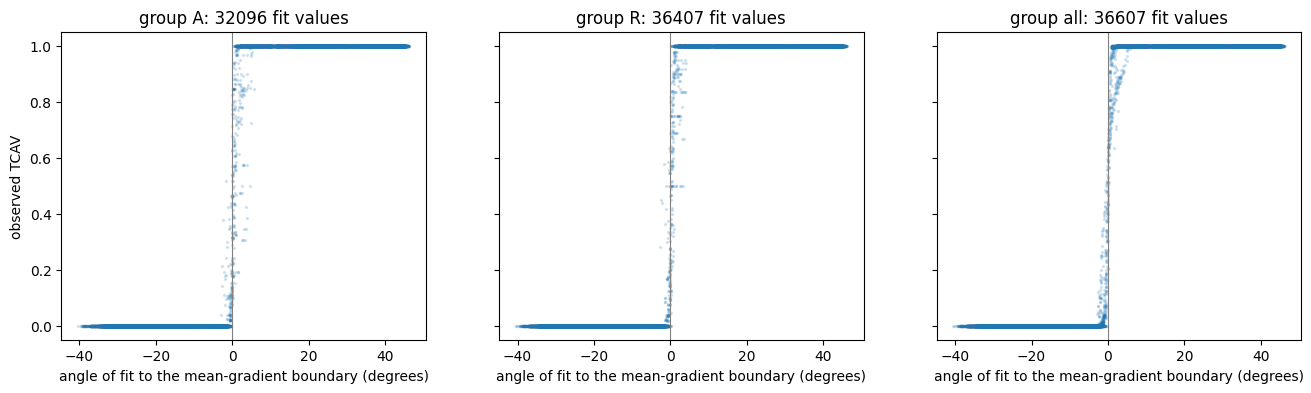

In [10]:
shown = predictions[predictions["group"].isin(HEADLINE_GROUPS) & (predictions["year"] <= paths.LAST_OUTCOME_YEAR)]
figure, axes = plt.subplots(1, len(HEADLINE_GROUPS), figsize=(16, 4), sharey=True)
for axis, group in zip(axes, HEADLINE_GROUPS):
    rows = shown[shown["group"] == group]
    axis.scatter(rows["angle_all_rows"], rows["observed_tcav"], s=2, alpha=0.15)
    axis.axvline(0, color="grey", lw=0.8)
    axis.set_title(f"group {group}: {len(rows)} fit values")
    axis.set_xlabel("angle of fit to the mean-gradient boundary (degrees)")
axes[0].set_ylabel("observed TCAV")
save_figure(figure, "test1_tcav_vs_angle")

Within one concept-group-year, how many of the fits sit on the minority side of the mean direction (0 = all fits agree)? And how close is each fit to the boundary compared with how spread the group's gradients are?

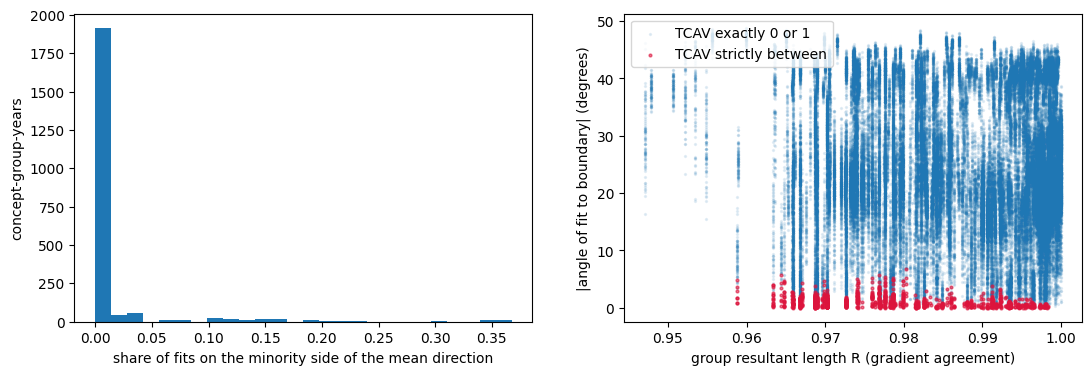

In [11]:
sides = shown.groupby(["concept", "estimator", "group", "year"])["predicted_all_rows"].mean()
minority = np.minimum(sides, 1 - sides)
figure, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(minority.dropna(), bins=26)
axes[0].set_xlabel("share of fits on the minority side of the mean direction")
axes[0].set_ylabel("concept-group-years")
interior = ~shown["endpoint"]
axes[1].scatter(shown.loc[~interior, "group_resultant_length"], shown.loc[~interior, "angle_own_group"].abs(),
                s=2, alpha=0.1, label="TCAV exactly 0 or 1")
axes[1].scatter(shown.loc[interior, "group_resultant_length"], shown.loc[interior, "angle_own_group"].abs(),
                s=4, alpha=0.6, color="crimson", label="TCAV strictly between")
axes[1].set_xlabel("group resultant length R (gradient agreement)")
axes[1].set_ylabel("|angle of fit to boundary| (degrees)")
axes[1].legend()
save_figure(figure, "test1_fit_disagreement_and_margin")

## Step 4 — Test 2: do random directions saturate too?

If saturation comes from the gradients alone, random unit directions should also give TCAV of 0 or 1. Per build-year, 2,000 directions in each of three families: uniform over all 192 dimensions, uniform in the span of the top-5 principal axes of that year's embeddings, and uniform in the orthogonal complement. TCAV is computed on all rows of the year and on each concept's A and R groups, and compared with the concept fits on the same rows. The interior share (strictly between 0.1 and 0.9) has a Monte Carlo standard error; group sizes are shown because a group of n rows can only reach multiples of 1/n.

In [12]:
step = time.time()
random_summary = []
for key, build in data.items():
    keys = [name for name, (owner, _) in concept_groups.items() if owner == key]
    labels = ["all"] + [f"{name}|{group}" for name in keys for group in ("A", "R")]
    masks = np.column_stack([np.ones(len(build["year"]), dtype=bool)] +
                            [concept_groups[name][1][:, GROUPS.index(group)] for name in keys for group in ("A", "R")])
    rng = geometry.build_rng(SEED, key[0], key[1], 0)
    build["axes"], build["random"] = {}, {}
    for year in YEARS:
        in_year = build["year"] == year
        if not in_year.any():
            continue
        build["axes"][year] = geometry.principal_axes(build["embeddings"][in_year])
        for family in geometry.DIRECTION_FAMILIES:
            sample = geometry.random_directions(rng, RANDOM_DIRECTIONS, build["axes"][year][1], TOP_AXES, family)
            build["random"][(year, family)] = sample
            share = geometry.positive_share(build["gradients"][in_year].astype(np.float64) @ sample.T, masks[in_year])
            for cell, label in enumerate(labels):
                rows = int(masks[in_year, cell].sum())
                if not rows:
                    continue
                inside, error = geometry.interior_share(share[cell], *INTERIOR)
                random_summary.append({"build": key[0], "reference": key[1], "panel": build["panel"], "year": year,
                                       "family": family, "population": label.split("|")[-1],
                                       "concept": label.split("|")[0] if "|" in label else "", "rows": rows,
                                       "share_exactly_0": float((share[cell] == 0).mean()),
                                       "share_exactly_1": float((share[cell] == 1).mean()),
                                       "interior_share": inside, "interior_se": error})
            if family == "isotropic":
                build.setdefault("random_tcav_all_rows", {})[year] = share[0]
random_summary = pd.DataFrame(random_summary)

In [13]:
concept_rows = predictions[predictions["group"].isin(HEADLINE_GROUPS)]
concept_summary = concept_rows.groupby(["build", "reference", "panel", "year", "group", "concept", "estimator"]).agg(
    rows=("rows", "first"), share_exactly_0=("observed_tcav", lambda v: float((v == 0).mean())),
    share_exactly_1=("observed_tcav", lambda v: float((v == 1).mean())),
    interior_share=("observed_tcav", lambda v: geometry.interior_share(v.to_numpy(), *INTERIOR)[0])).reset_index()
concept_summary = concept_summary.rename(columns={"group": "population"})
concept_summary["family"] = "concept fits (" + concept_summary.pop("estimator") + ")"
saturation = pd.concat([random_summary, concept_summary], ignore_index=True)
saturation.to_csv(OUTPUT / "random_direction_saturation.csv", index=False)
timings["test2"] = time.time() - step
saturation[saturation["year"] <= paths.LAST_OUTCOME_YEAR].groupby(["panel", "population", "family"]).agg(
    cells=("interior_share", "size"), median_rows=("rows", "median"), share_exactly_0=("share_exactly_0", "mean"),
    share_exactly_1=("share_exactly_1", "mean"), interior_share=("interior_share", "mean"),
    largest_mc_se=("interior_se", "max"))

cells  median_rows  \
panel     population family                                             
auxiliary A          complement                      107         28.0   
                     concept fits (all_negatives)    101         30.0   
                     concept fits (legacy)           101         30.0   
                     isotropic                       107         28.0   
                     top                             107         28.0   
          R          complement                      114         25.5   
                     concept fits (all_negatives)    107         26.0   
                     concept fits (legacy)           107         26.0   
                     isotropic                       114         25.5   
                     top                             114         25.5   
          all        complement                       14        321.0   
                     concept fits (all_negatives)    107        320.0   
                     concept fits (legacy)           107        320.0   
                     isotropic                        14        321.0   
                     top                              14        321.0   
primary   A          complement                      232         36.5   
                     concept fits (all_negatives)    229         37.0   
                     concept fits (legacy)           229         37.0   
                     isotropic                       232         36.5   
                     top                             232         36.5   
          R          complement                      272         30.0   
                     concept fits (all_negatives)    269         30.0   
                     concept fits (legacy)           269         30.0   
                     isotropic                       272         30.0   
                     top                             272         30.0   
          all        complement                       35        319.0   
                     concept fits (all_negatives)    271        322.0   
                     concept fits (legacy)           271        322.0   
                     isotropic                        35        319.0   
                     top                              35        319.0   

                                                   share_exactly_0  \
panel     population family                                          
auxiliary A          complement                           0.419393   
                     concept fits (all_negatives)         0.494653   
                     concept fits (legacy)                0.494983   
                     isotropic                            0.440075   
                     top                                  0.481659   
          R          complement                           0.430526   
                     concept fits (all_negatives)         0.522991   
                     concept fits (legacy)                0.524860   
                     isotropic                            0.448035   
                     top                                  0.484351   
          all        complement                           0.324250   
                     concept fits (all_negatives)         0.522991   
                     concept fits (legacy)                0.523115   
                     isotropic                            0.370107   
                     top                                  0.458500   
primary   A          complement                           0.390024   
                     concept fits (all_negatives)         0.550170   
                     concept fits (legacy)                0.533877   
                     isotropic                            0.417498   
                     top                                  0.474114   
          R          complement                           0.404750   
                     concept fits (all_negatives)         0.583385   
                     concept fits 

In [14]:
# Tests 1-2 with 2015 (no outcome needed for TCAV) shown next to the years to 2014
def period(table):
    return np.where(table["year"] <= paths.LAST_OUTCOME_YEAR, f"to {paths.LAST_OUTCOME_YEAR}", "2015")


display(predictions.assign(period=period(predictions)).groupby(["panel", "estimator", "group", "period"]).agg(
    fit_values=("observed_tcav", "size"), endpoint_share=("endpoint", "mean"),
    matches_all_rows=("matches_all_rows", "mean"), matches_own_group=("matches_own_group", "mean")))
saturation.assign(period=period(saturation)).groupby(["panel", "population", "family", "period"]).agg(
    cells=("interior_share", "size"), median_rows=("rows", "median"), share_exactly_0=("share_exactly_0", "mean"),
    share_exactly_1=("share_exactly_1", "mean"), interior_share=("interior_share", "mean"))

fit_values  endpoint_share  \
panel     estimator     group   period                                
auxiliary all_negatives A       2015           1217        0.998357   
                                to 2014        4876        0.998769   
                        R       2015           1483        0.998651   
                                to 2014        5060        0.998814   
                        R+A+    2015           1217        0.999178   
                                to 2014        4634        0.998705   
                        R+A-    2015           1259        1.000000   
                                to 2014        4290        0.999767   
                        R-A+    2015            974        0.998973   
                                to 2014        4583        0.998691   
                        all     2015           1483        0.998651   
                                to 2014        5060        0.998814   
                        neither 2015           1483        0.998651   
                                to 2014        5060        0.998814   
          legacy        A       2015           1217        0.995892   
                                to 2014        4876        0.996719   
                        R       2015           1483        0.997303   
                                to 2014        5060        0.997628   
                        R+A+    2015           1217        0.997535   
                                to 2014        4634        0.997410   
                        R+A-    2015           1259        0.999206   
                                to 2014        4290        0.999534   
                        R-A+    2015            974        0.994867   
                                to 2014        4583        0.996727   
                        all     2015           1483        0.996628   
                                to 2014        5060        0.996640   
                        neither 2015           1483        0.997303   
                                to 2014        5060        0.997036   
primary   all_negatives A       2015           2354        0.988105   
                                to 2014       11175        0.990246   
                        R       2015           2853        0.984578   
                                to 2014       13147        0.991861   
                        R+A+    2015           2225        0.988315   
                                to 2014       10880        0.991360   
                        R+A-    2015           2555        0.985910   
                                to 2014       11050        0.994842   
                        R-A+    2015           1904        0.988971   
                                to 2014       10175        0.993710   
                        all     2015           3003        0.980020   
                                to 2014       13247        0.987242   
                        neither 2015           2953        0.980359   
                                to 2014       12947        0.987642   
          legacy        A       2015           2353        0.982150   
                                to 2014       11169        0.982541   
                        R       2015           2852        0.977209   
                                to 2014       13140        0.986758   
                        R+A+    2015           2225        0.985618   
                                to 2014       10879        0.986028   
                        R+A-    2015           2554        0.978857   
                                to 2014       11043        0.994023   
                        R-A+    2015           1903        0.985812   
                                to 2014       10169        0.986921   
                        all     2015           3002        0.969021   
                                to 2014       13240        0.974547   
                        neither 2015           2952        0.9695

cells  median_rows  \
panel     population family                       period                        
auxiliary A          complement                   2015        26         28.0   
                                                  to 2014    107         28.0   
                     concept fits (all_negatives) 2015        25         28.0   
                                                  to 2014    101         30.0   
                     concept fits (legacy)        2015        25         28.0   
                                                  to 2014    101         30.0   
                     isotropic                    2015        26         28.0   
                                                  to 2014    107         28.0   
                     top                          2015        26         28.0   
                                                  to 2014    107         28.0   
          R          complement                   2015        32         22.5   
                                                  to 2014    114         25.5   
                     concept fits (all_negatives) 2015        31         25.0   
                                                  to 2014    107         26.0   
                     concept fits (legacy)        2015        31         25.0   
                                                  to 2014    107         26.0   
                     isotropic                    2015        32         22.5   
                                                  to 2014    114         25.5   
                     top                          2015        32         22.5   
                                                  to 2014    114         25.5   
          all        complement                   2015         4        282.5   
                                                  to 2014     14        321.0   
                     concept fits (all_negatives) 2015        31        272.0   
                                                  to 2014    107        320.0   
                     concept fits (legacy)        2015        31        272.0   
                                                  to 2014    107        320.0   
                     isotropic                    2015         4        282.5   
                                                  to 2014     14        321.0   
                     top                          2015         4        282.5   
                                                  to 2014     14        321.0   
primary   A          complement                   2015        48         30.5   
                                                  to 2014    232         36.5   
                     concept fits (all_negatives) 2015        48         30.5   
                                                  to 2014    229         37.0   
                     concept fits (legacy)        2015        48         30.5   
                                                  to 2014    229         37.0   
                     isotropic                    2015        48         30.5   
                                                  to 2014    232         36.5   
                     top                          2015        48         30.5   
                                                  to 2014    232         36.5   
          R          complement                   2015        59         21.0   
                                                  to 2014    272         30.0   
                     concept fits (all_negatives) 2015        58         23.0   
                                                  to 2014    269         30.0   
                     concept fits (legacy)        2015        58         23.0   
                                                  to 2014    269         30.0   
                     isotropic                    2015        59         21.0   
                                                  to 2014    272         30.0   
         

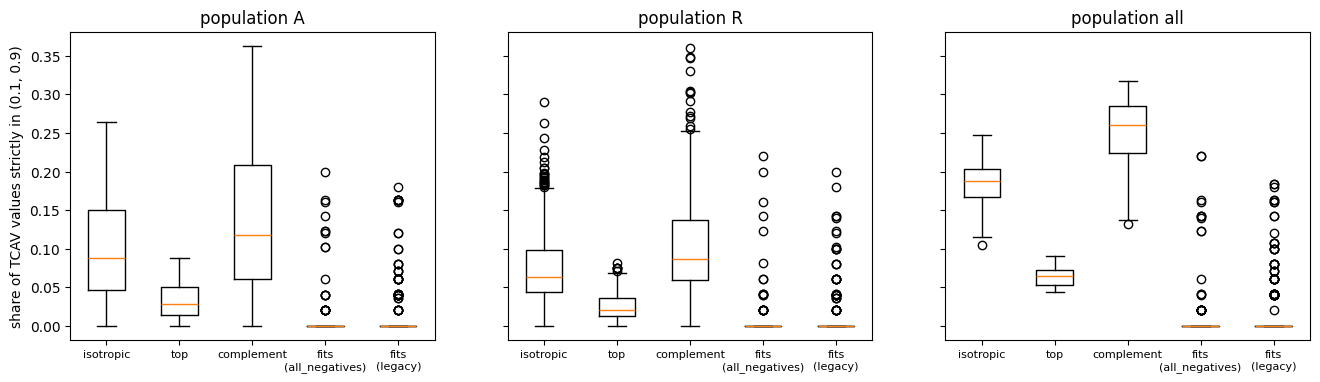

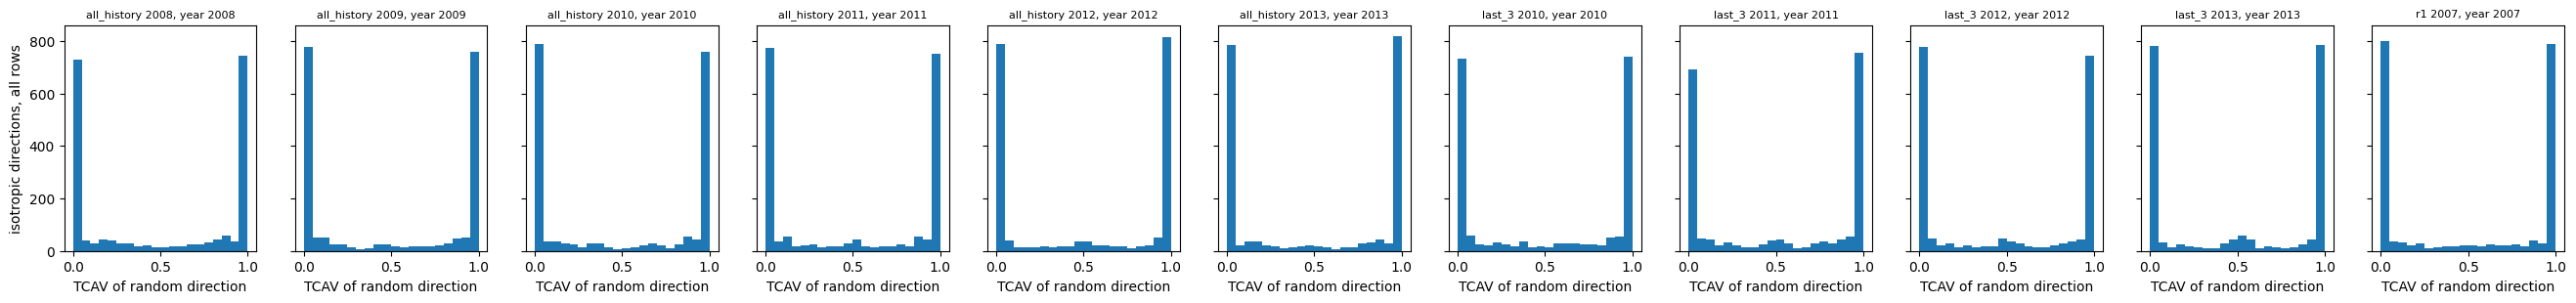

In [15]:
outcome_years = saturation[saturation["year"] <= paths.LAST_OUTCOME_YEAR]
families = list(geometry.DIRECTION_FAMILIES) + sorted(f for f in saturation["family"].unique() if f.startswith("concept"))
figure, axes = plt.subplots(1, len(HEADLINE_GROUPS), figsize=(16, 4), sharey=True)
for axis, population in zip(axes, HEADLINE_GROUPS):
    rows = outcome_years[outcome_years["population"] == population]
    values = [rows.loc[rows["family"] == f, "interior_share"].dropna() for f in families]
    axis.boxplot(values, tick_labels=[f.replace("concept fits ", "fits\n") for f in families])
    axis.set_title(f"population {population}")
    axis.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("share of TCAV values strictly in (0.1, 0.9)")
save_figure(figure, "test2_interior_share_by_family")

figure, axes = plt.subplots(1, len(data), figsize=(3 * len(data), 3), sharey=True, squeeze=False)
for axis, (key, build) in zip(axes[0], data.items()):
    year = key[1]
    axis.hist(build["random_tcav_all_rows"][year], bins=np.linspace(0, 1, 21))
    axis.set_title(f"{key[0]} {key[1]}, year {year}", fontsize=8)
    axis.set_xlabel("TCAV of random direction")
axes[0, 0].set_ylabel("isotropic directions, all rows")
save_figure(figure, "test2_isotropic_histograms_reference_year")

## Step 5 — Test 3: which data axes carry the sign?

Split each fit v into its part inside the span of the top-k principal axes of the year's embeddings (v_in) and the rest (v_out), for k = 1..10. The two derivatives add up to the full one. If the sign comes from a few data axes, TCAV of v_in should already equal the full TCAV for small k.

Gradient dimensionality: participation ratio tr(M)²/tr(M²) of the centred covariance and the uncentred second moment, and the share of gradient energy in the top-k axes against chance k/192. Raw coordinates are the frame of the measured score; the standardized chart (z = (h − mean) / scale of the reference SAE scaler) links to the earlier "≈ 4 dimensions" figure. Dot products, and so every TCAV sign, are the same in both charts.

In [16]:
step = time.time()
projection = []
for fit in fits:
    build = data[fit["key"]]
    for year in YEARS:
        in_year = build["year"] == year
        if not in_year.any():
            continue
        axes = build["axes"][year][1]
        gradients = build["gradients"][in_year].astype(np.float64)
        full = gradients @ fit["directions"].T
        for k in PROJECTION_AXES:
            inside, outside = geometry.split_direction(fit["directions"], axes, k)
            parts = {"inside": gradients @ inside.T, "outside": gradients @ outside.T}
            if not np.allclose(parts["inside"] + parts["outside"], full):
                errors.append(f"{fit['concept']} {year} k={k}: projection parts do not add up")
            for group in GROUPS:
                rows = fit["groups"][in_year, GROUPS.index(group)]
                if not rows.any():
                    continue
                tcav_full = (full[rows] > 0).mean(axis=0)
                record = {"build": fit["key"][0], "reference": fit["key"][1], "panel": fit["panel"],
                          "concept": fit["concept"], "estimator": fit["estimator"], "group": group, "year": year,
                          "k": k, "rows": int(rows.sum()), "tcav_full_median": float(np.median(tcav_full)),
                          "inside_norm_median": float(np.median(np.linalg.norm(inside, axis=1)))}
                for part, values in parts.items():
                    tcav_part = (values[rows] > 0).mean(axis=0)
                    record[f"tcav_{part}_median"] = float(np.median(tcav_part))
                    record[f"mean_abs_tcav_change_{part}"] = float(np.mean(np.abs(tcav_part - tcav_full)))
                    record[f"row_sign_agreement_{part}"] = float(np.mean((values[rows] > 0) == (full[rows] > 0)))
                projection.append(record)
projection = pd.DataFrame(projection)
projection.to_csv(OUTPUT / "projection_split.csv", index=False)
projection[projection["year"] <= paths.LAST_OUTCOME_YEAR].groupby(["panel", "group", "k"])[
    ["row_sign_agreement_inside", "row_sign_agreement_outside", "mean_abs_tcav_change_inside",
     "mean_abs_tcav_change_outside", "inside_norm_median"]].mean().unstack("group").round(3)

row_sign_agreement_inside                                     \
group                                A      R   R+A+   R+A-   R-A+    all   
panel     k                                                                 
auxiliary 1                      0.970  0.972  0.969  0.967  0.970  0.972   
          2                      0.998  0.999  0.998  0.999  0.998  0.998   
          3                      0.998  0.999  0.998  0.999  0.998  0.999   
          4                      0.998  0.999  0.999  0.999  0.998  0.999   
          5                      0.998  0.999  0.998  0.999  0.998  0.999   
          6                      0.998  0.998  0.998  0.999  0.998  0.998   
          7                      0.997  0.997  0.996  0.997  0.996  0.997   
          8                      0.997  0.997  0.997  0.998  0.997  0.998   
          9                      0.998  0.999  0.998  0.999  0.998  0.998   
          10                     0.998  0.999  0.999  0.999  0.998  0.998   
primary   1                      0.959  0.965  0.958  0.971  0.967  0.965   
          2                      0.987  0.989  0.987  0.989  0.991  0.988   
          3                      0.981  0.984  0.980  0.984  0.987  0.983   
          4                      0.982  0.985  0.981  0.985  0.986  0.984   
          5                      0.986  0.989  0.986  0.989  0.991  0.988   
          6                      0.988  0.990  0.988  0.990  0.992  0.990   
          7                      0.991  0.993  0.991  0.993  0.994  0.993   
          8                      0.992  0.993  0.992  0.993  0.994  0.993   
          9                      0.994  0.995  0.994  0.995  0.996  0.995   
          10                     0.994  0.995  0.994  0.995  0.996  0.995   

                     row_sign_agreement_outside                ...  \
group        neither                          A      R   R+A+  ...   
panel     k                                                    ...   
auxiliary 1    0.972                      0.615  0.576  0.636  ...   
          2    0.998                      0.413  0.377  0.410  ...   
          3    0.998                      0.437  0.418  0.412  ...   
          4    0.998                      0.437  0.431  0.432  ...   
          5    0.998                      0.434  0.414  0.453  ...   
          6    0.998                      0.412  0.396  0.432  ...   
          7    0.997                      0.365  0.360  0.396  ...   
          8    0.998                      0.374  0.372  0.407  ...   
          9    0.998                      0.407  0.403  0.442  ...   
          10   0.998                      0.403  0.393  0.439  ...   
primary   1    0.965                      0.510  0.465  0.526  ...   
          2    0.988                      0.335  0.285  0.338  ...   
          3    0.983                      0.348  0.313  0.354  ...   
          4    0.983                      0.366  0.334  0.380  ...   
          5    0.988                      0.330  0.300  0.353  ...   
          6    0.989                      0.313  0.290  0.334  ...   
          7    0.993                      0.307  0.284  0.322  ...   
          8    0.993                      0.327  0.303  0.337  ...   
          9    0.995                      0.335  0.319  0.351  ...   
          10   0.995                      0.328  0.323  0.341  ...   

             mean_abs_tcav_change_outside                inside_norm_median  \
group                                R-A+    all neither                  A   
panel     k                                                                   
auxiliary 1                         0.380  0.413   0.411              0.632   
          2                         0.588  0.589   0.591              0.847   
          3                         0.544  0.571   0.567              0.943   
          4                         0.544  0.617   0.617              0.974   
          5                         0.552  0.633   0.633              0.982  

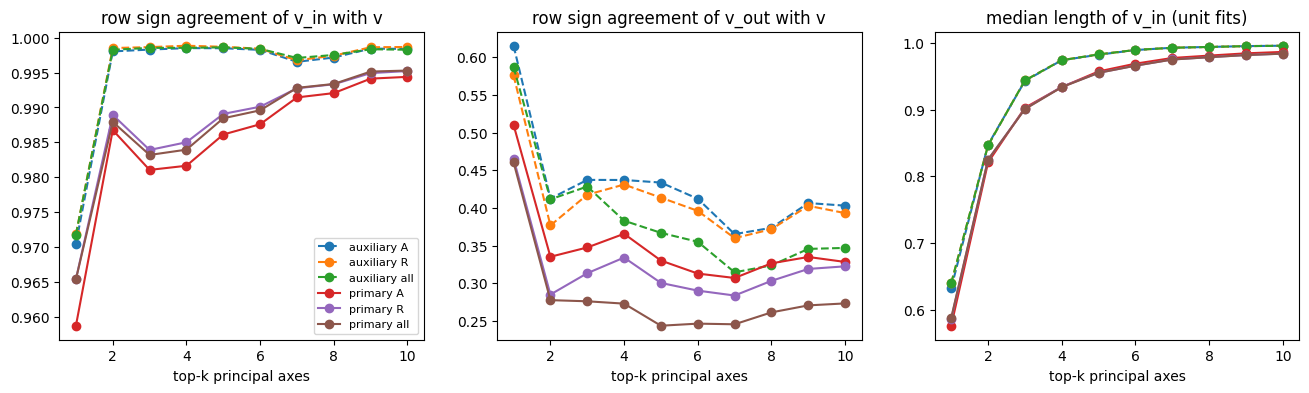

In [17]:
headline = projection[(projection["year"] <= paths.LAST_OUTCOME_YEAR) & projection["group"].isin(HEADLINE_GROUPS)]
curves = headline.groupby(["panel", "group", "k"]).mean(numeric_only=True)
figure, axes = plt.subplots(1, 3, figsize=(16, 4))
for (panel_name, group), rows in curves.groupby(level=["panel", "group"]):
    style = "-" if panel_name == "primary" else "--"
    k = rows.index.get_level_values("k")
    axes[0].plot(k, rows["row_sign_agreement_inside"], style, marker="o", label=f"{panel_name} {group}")
    axes[1].plot(k, rows["row_sign_agreement_outside"], style, marker="o", label=f"{panel_name} {group}")
    axes[2].plot(k, rows["inside_norm_median"], style, marker="o", label=f"{panel_name} {group}")
for axis, title in zip(axes, ("row sign agreement of v_in with v", "row sign agreement of v_out with v",
                              "median length of v_in (unit fits)")):
    axis.set_title(title)
    axis.set_xlabel("top-k principal axes")
axes[0].legend(fontsize=8)
save_figure(figure, "test3_projection_curves")

In [18]:
dimension, energy, spectrum = [], [], []
for key, build in data.items():
    for year in YEARS:
        in_year = build["year"] == year
        if not in_year.any():
            continue
        embeddings = build["embeddings"][in_year].astype(np.float64)
        block = [fit["directions"] for fit in fits if fit["key"] == key]
        stacked = np.concatenate(block) if block else np.zeros((0, embeddings.shape[1]))
        for chart in ("raw", "standardized"):
            scale = np.ones_like(build["scale"]) if chart == "raw" else build["scale"]
            chart_embeddings = embeddings / scale
            _, axes, variances = geometry.principal_axes(chart_embeddings)
            spectrum.append({"build": key[0], "reference": key[1], "year": year, "chart": chart,
                             "embedding_participation_ratio": geometry.participation_ratio(np.diag(variances)),
                             **{f"variance_share_axis_{i + 1}": v for i, v in enumerate(variances[:20] / variances.sum())}})
            for gradient_scale, values in (("probability", build["gradients"][in_year]), ("log_odds", build["log_odds"][in_year])):
                chart_gradients, chart_directions = geometry.standardized_chart(values.astype(np.float64), stacked, scale)
                before, after = values.astype(np.float64) @ stacked.T, chart_gradients @ chart_directions.T
                if not np.allclose(before, after, equal_nan=True):
                    errors.append(f"{key} {year} {chart} {gradient_scale}: gradient . direction changed in the chart")
                derivative_difference = float(np.nanmax(np.abs(before - after))) if before.size else 0.0
                centred, uncentred = geometry.gradient_moments(chart_gradients)
                dimension.append({"build": key[0], "reference": key[1], "panel": build["panel"], "year": year,
                                  "chart": chart, "gradient_scale": gradient_scale,
                                  "participation_ratio_centred": geometry.participation_ratio(centred),
                                  "participation_ratio_uncentred": geometry.participation_ratio(uncentred),
                                  "max_abs_derivative_difference": derivative_difference})
                for k in PROJECTION_AXES:
                    energy.append({"build": key[0], "reference": key[1], "panel": build["panel"], "year": year,
                                   "chart": chart, "gradient_scale": gradient_scale, "k": k,
                                   "energy_share": geometry.energy_share(chart_gradients, axes, k),
                                   "chance": k / axes.shape[0]})
dimension, energy, spectrum = pd.DataFrame(dimension), pd.DataFrame(energy), pd.DataFrame(spectrum)
dimension.to_csv(OUTPUT / "gradient_dimension.csv", index=False)
energy.to_csv(OUTPUT / "gradient_energy.csv", index=False)
spectrum.to_csv(OUTPUT / "embedding_spectrum.csv", index=False)
timings["test3"] = time.time() - step
display(spectrum.groupby("chart")[["embedding_participation_ratio", "variance_share_axis_1",
                                   "variance_share_axis_5"]].describe().T.round(3))
dimension.groupby(["chart", "gradient_scale"])[["participation_ratio_centred", "participation_ratio_uncentred",
                                                 "max_abs_derivative_difference"]].describe().round(2)

chart                                   raw  standardized
embedding_participation_ratio count  60.000        60.000
                              mean    2.601         4.046
                              std     0.377         0.486
                              min     1.903         2.805
                              25%     2.330         3.835
                              50%     2.585         4.153
                              75%     2.824         4.380
                              max     3.462         4.925
variance_share_axis_1         count  60.000        60.000
                              mean    0.577         0.409
                              std     0.066         0.055
                              min     0.413         0.324
                              25%     0.537         0.369
                              50%     0.579         0.404
                              75%     0.617         0.430
                              max     0.707         0.555
variance_share_axis_5         count  60.000        60.000
                              mean    0.028         0.050
                              std     0.007         0.010
                              min     0.014         0.028
                              25%     0.023         0.044
                              50%     0.027         0.050
                              75%     0.032         0.056
                              max     0.044         0.073

participation_ratio_centred                    \
                                                  count  mean   std   min   
chart        gradient_scale                                                 
raw          log_odds                              60.0  1.15  0.05  1.07   
             probability                           60.0  1.08  0.01  1.05   
standardized log_odds                              60.0  1.12  0.07  1.05   
             probability                           60.0  1.03  0.01  1.01   

                                                     \
                              25%   50%   75%   max   
chart        gradient_scale                           
raw          log_odds        1.12  1.14  1.19  1.29   
             probability     1.07  1.07  1.09  1.12   
standardized log_odds        1.08  1.10  1.15  1.35   
             probability     1.02  1.03  1.03  1.06   

                            participation_ratio_uncentred        ...        \
                                                    count  mean  ...   75%   
chart        gradient_scale                                      ...         
raw          log_odds                                60.0  1.07  ...  1.08   
             probability                             60.0  1.09  ...  1.11   
standardized log_odds                                60.0  1.02  ...  1.03   
             probability                             60.0  1.03  ...  1.03   

                                  max_abs_derivative_difference            \
                              max                         count mean  std   
chart        gradient_scale                                                 
raw          log_odds        1.12                          60.0  0.0  0.0   
             probability     1.15                          60.0  0.0  0.0   
standardized log_odds        1.03                          60.0  0.0  0.0   
             probability     1.05                          60.0  0.0  0.0   

                                                      
                             min  25%  50%  75%  max  
chart        gradient_scale                           
raw          log_odds        0.0  0.0  0.0  0.0  0.0  
             probability     0.0  0.0  0.0  0.0  0.0  
standardized log_odds        0.0  0.0  0.0  0.0  0.0  
             probability     0.0  0.0  0.0  0.0  0.0  

[4 rows x 24 columns]

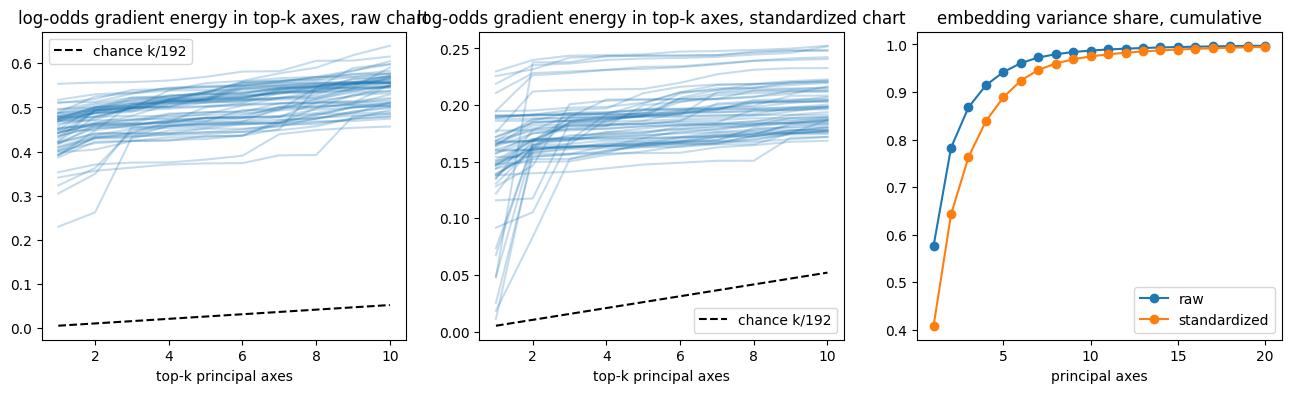

In [19]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4))
for chart, axis in zip(("raw", "standardized"), axes[:2]):
    rows = energy[(energy["chart"] == chart) & (energy["gradient_scale"] == "log_odds")]
    for (build, reference, year), curve in rows.groupby(["build", "reference", "year"]):
        axis.plot(curve["k"], curve["energy_share"], color="tab:blue", alpha=0.25)
    axis.plot(rows.groupby("k")["chance"].first(), "k--", label="chance k/192")
    axis.set_title(f"log-odds gradient energy in top-k axes, {chart} chart")
    axis.set_xlabel("top-k principal axes")
    axis.legend()
for chart, rows in spectrum.groupby("chart"):
    shares = rows[[f"variance_share_axis_{i}" for i in range(1, 21)]].mean()
    axes[2].plot(range(1, 21), shares.cumsum(), marker="o", label=chart)
axes[2].set_title("embedding variance share, cumulative")
axes[2].set_xlabel("principal axes")
axes[2].legend()
save_figure(figure, "test3_energy_and_spectrum")

## Step 6 — Test 4: does the shared direction persist away from the data?

Only for builds whose head replay matched (step 2). Per build-year, with μ the mean of the year's evaluation embeddings and L the root mean squared spread of the data inside the top-5 principal axes, three ways to move the rows, at scales s = 0, 0.25, 0.5, 1, 2, 4:

- **off-axis noise:** h + sL ξ, with ξ a random unit direction outside the top-5 axes;
- **full-space noise:** h + sL ξ, with ξ a random unit direction anywhere;
- **dilation:** μ + s(h − μ): s = 1 leaves the rows unchanged, s = 0 puts them all at the mean, s > 1 spreads them out.

One noise draw per row is reused at every scale. Group membership is held fixed. These curves describe only the sampled neighbourhood: they cannot prove the head is linear everywhere, and moved embeddings are model diagnostics, not patients.

In [20]:
step = time.time()
perturbation = []
for key, build in data.items():
    if not build.get("replayed"):
        errors.append(f"{key}: no perturbation test because the head replay did not match")
        continue
    block = [fit for fit in fits if fit["key"] == key]
    rng = geometry.build_rng(SEED, key[0], key[1], 1)
    stacked = np.concatenate([fit["directions"] for fit in block]) if block else np.zeros((0, 192))
    edges = np.cumsum([0] + [len(fit["directions"]) for fit in block])
    for year in YEARS:
        in_year = build["year"] == year
        if not in_year.any():
            continue
        embeddings = build["embeddings"][in_year].astype(np.float64)
        mean, axes, _ = build["axes"][year]
        length = geometry.top_axes_length(embeddings, mean, axes, TOP_AXES)
        noise = geometry.noise_draws(rng, embeddings, axes, TOP_AXES)
        original = pilot.batched_death_probabilities(build["continuation"], embeddings.astype(np.float32), BATCH_ROWS)[:, 1]
        for family in geometry.PERTURBATION_FAMILIES:
            for scale in SCALES:
                moved = geometry.perturb(embeddings, mean, noise, length, scale, family).astype(np.float32)
                record = {"build": key[0], "reference": key[1], "panel": build["panel"], "year": year,
                          "family": family, "scale": scale, "rows": int(in_year.sum()), "spread_L": length,
                          "mean_displacement": float(np.linalg.norm(moved - embeddings, axis=1).mean())}
                try:   # the pilot functions raise when any output or gradient row is not finite
                    probability = pilot.batched_death_probabilities(build["continuation"], moved, BATCH_ROWS)[:, 1]
                    gradients = pilot.batched_death_gradients(build["continuation"], moved, BATCH_ROWS).astype(np.float64)
                except RuntimeError as error:
                    errors.append(f"{key} {year} {family} {scale}: {error}")
                    record["head_output_finite"] = False   # every measured quantity stays missing (NaN)
                    perturbation.append(record)
                    continue
                summary = geometry.coherence(gradients)
                record.update({"head_output_finite": True,
                          "finite_probability_rows": int(np.isfinite(probability).sum()),
                          "finite_nonzero_gradient_rows": summary["rows_used"],
                          "median_abs_probability_change": float(np.nanmedian(np.abs(probability - original))),
                          "resultant_length": summary["resultant_length"], "leading_share": summary["leading_share"]})
                sensitivity = gradients @ stacked.T
                for group in GROUPS:
                    values, matches = [], []
                    for fit, start, end in zip(block, edges[:-1], edges[1:]):
                        rows = fit["groups"][in_year, GROUPS.index(group)]
                        if not rows.any():
                            continue
                        tcav = geometry.positive_share(sensitivity[:, start:end], rows[:, None])[0]
                        values.append(tcav)
                        matches.append(tcav == geometry.predicted_tcav(summary["mean_direction"], fit["directions"]))
                        if (family, scale) in (("off_axis", 0.0), ("dilation", 1.0)):
                            difference = np.abs(tcav - fit["tcav"][GROUPS.index(group), YEARS.index(year)])
                            record[f"baseline_max_tcav_difference_{group}"] = max(
                                record.get(f"baseline_max_tcav_difference_{group}", 0.0), float(difference.max()))
                    if values:
                        values = np.concatenate(values)
                        record[f"concept_interior_share_{group}"] = geometry.interior_share(values, *INTERIOR)[0]
                        record[f"concept_endpoint_share_{group}"] = float(np.isin(values, (0.0, 1.0)).mean())
                        record[f"concept_matches_mean_direction_{group}"] = float(np.concatenate(matches).mean())
                for direction_family in geometry.DIRECTION_FAMILIES:
                    shares = geometry.positive_share(gradients @ build["random"][(year, direction_family)].T,
                                                     np.ones((len(gradients), 1), dtype=bool))[0]
                    record[f"random_interior_share_{direction_family}"] = geometry.interior_share(shares, *INTERIOR)[0]
                perturbation.append(record)
perturbation = pd.DataFrame(perturbation)
perturbation.to_csv(OUTPUT / "perturbation_curves.csv", index=False)
timings["test4"] = time.time() - step
baseline = perturbation[((perturbation["family"] == "off_axis") & (perturbation["scale"] == 0))
                        | ((perturbation["family"] == "dilation") & (perturbation["scale"] == 1))]
baseline.filter(regex="baseline_max_tcav_difference").describe()

,baseline_max_tcav_difference_A,baseline_max_tcav_difference_R,baseline_max_tcav_difference_R+A+,baseline_max_tcav_difference_R+A-,baseline_max_tcav_difference_R-A+,baseline_max_tcav_difference_neither,baseline_max_tcav_difference_all
count,120.0,120.0,120.0,120.0,120.0,120.0,120.0
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0


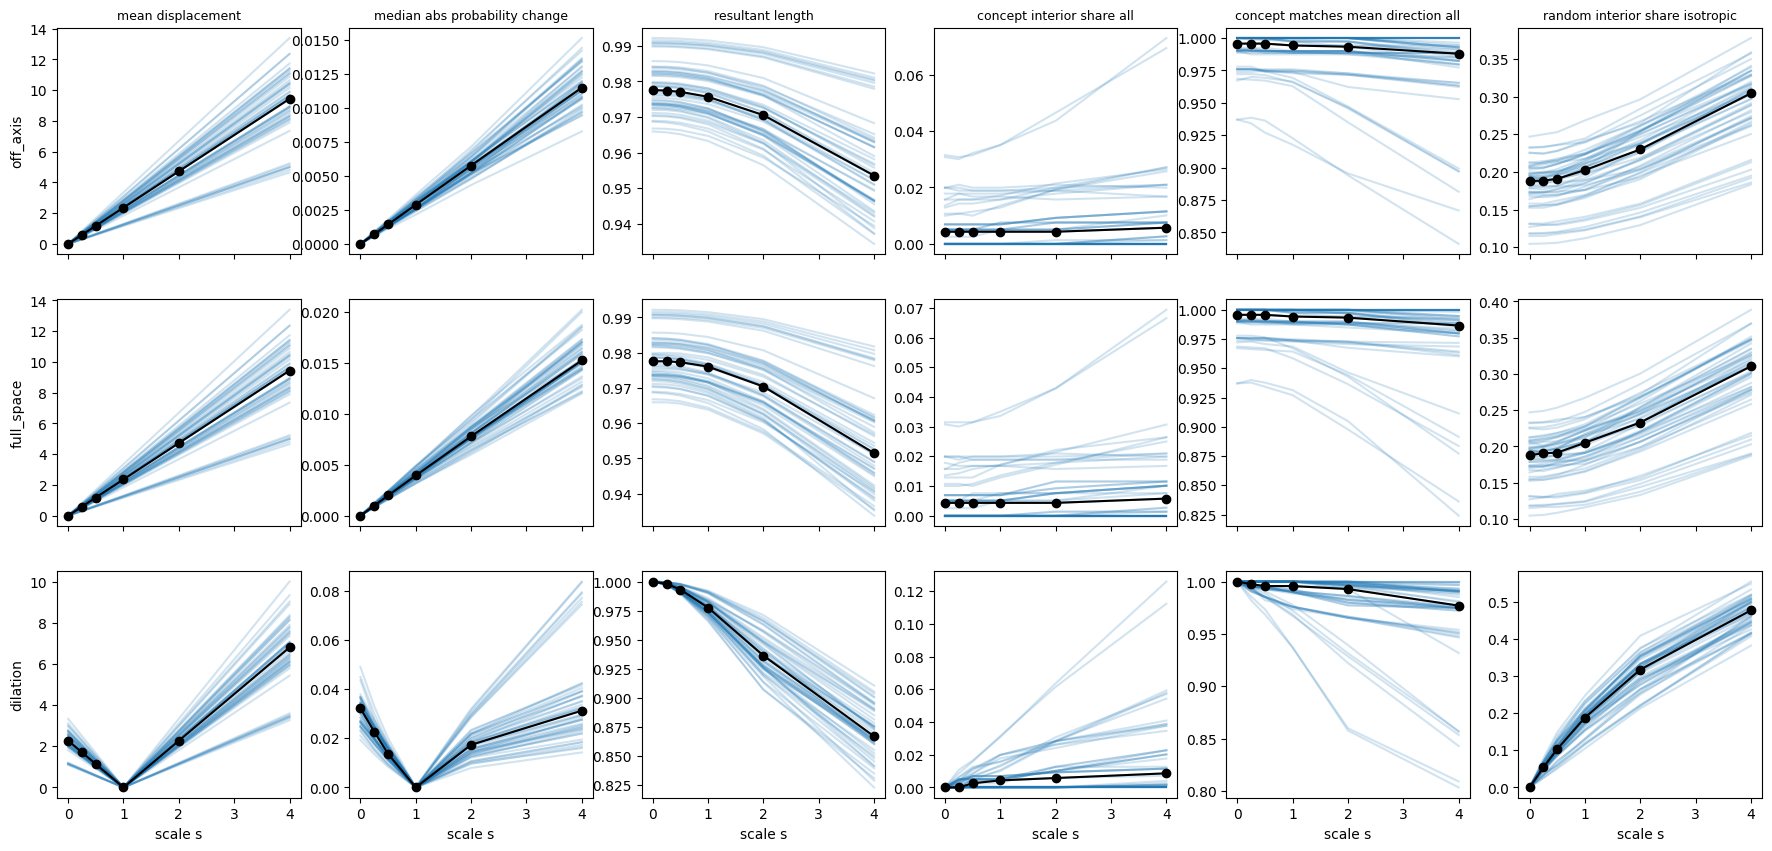

mean_displacement  median_abs_probability_change  \
panel     family     scale                                                     
auxiliary dilation   0.00               2.036                          0.031   
                     0.25               1.527                          0.022   
                     0.50               1.018                          0.014   
                     1.00               0.000                          0.000   
                     2.00               2.036                          0.020   
                     4.00               6.107                          0.036   
          full_space 0.00               0.000                          0.000   
                     0.25               0.520                          0.001   
                     0.50               1.041                          0.002   
                     1.00               2.082                          0.004   
                     2.00               4.164                          0.008   
                     4.00               8.327                          0.016   
          off_axis   0.00               0.000                          0.000   
                     0.25               0.520                          0.001   
                     0.50               1.041                          0.001   
                     1.00               2.082                          0.003   
                     2.00               4.164                          0.006   
                     4.00               8.327                          0.012   
primary   dilation   0.00               2.369                          0.032   
                     0.25               1.777                          0.023   
                     0.50               1.185                          0.014   
                     1.00               0.000                          0.000   
                     2.00               2.369                          0.016   
                     4.00               7.107                          0.028   
          full_space 0.00               0.000                          0.000   
                     0.25               0.619                          0.001   
                     0.50               1.239                          0.002   
                     1.00               2.477                          0.004   
                     2.00               4.955                          0.008   
                     4.00               9.910                          0.015   
          off_axis   0.00               0.000                          0.000   
                     0.25               0.619                          0.001   
                     0.50               1.239                          0.001   
                     1.00               2.477                          0.003   
                     2.00               4.955                          0.006   
                     4.00               9.910                          0.011   

                            resultant_length  concept_interior_share_all  \
panel     family     scale                                                 
auxiliary dilation   0.00              1.000                       0.000   
                     0.25              0.999                       0.000   
                     0.50              0.995                       0.000   
                     1.00              0.982                       0.000   
                     2.00              0.948                       0.000   
                     4.00              0.883                       0.003   
          full_space 0.00              0.982                       0.000   
                     0.25              0.982                       0.000   
                     0.50              0.982                       0.000   
                     1.00              0.981                       0.000   
                     2.00              0.976                       0.001   

In [21]:
outcome_years = perturbation[perturbation["year"] <= paths.LAST_OUTCOME_YEAR]
columns = ("mean_displacement", "median_abs_probability_change", "resultant_length",
           "concept_interior_share_all", "concept_matches_mean_direction_all", "random_interior_share_isotropic")
figure, axes = plt.subplots(len(geometry.PERTURBATION_FAMILIES), len(columns), figsize=(22, 10), sharex=True)
for row, family in enumerate(geometry.PERTURBATION_FAMILIES):
    rows = outcome_years[outcome_years["family"] == family]
    for column, name in enumerate(columns):
        axis = axes[row, column]
        for _, curve in rows.groupby(["build", "reference", "year"]):
            axis.plot(curve["scale"], curve[name], color="tab:blue", alpha=0.2)
        axis.plot(rows.groupby("scale")[name].median(), "k-o", label="median")
        if row == 0:
            axis.set_title(name.replace("_", " "), fontsize=9)
        if column == 0:
            axis.set_ylabel(family)
for axis in axes[-1]:
    axis.set_xlabel("scale s")
save_figure(figure, "test4_perturbation_curves")
outcome_years.groupby(["panel", "family", "scale"])[list(columns)].median().round(3)

## Step 7 — Run record

In [22]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


commit = subprocess.run(["git", "rev-parse", "HEAD"], cwd=CODE_ROOT, capture_output=True, text=True).stdout.strip()
uncommitted = subprocess.run(["git", "status", "--porcelain", "--", "tcav_geometry.py", "tcav_geometry.ipynb",
                              "tests/test_tcav_geometry.py"], cwd=CODE_ROOT, capture_output=True, text=True).stdout.split("\n")
record = {
    "notebook": "tcav_geometry.ipynb", "started": started,
    "finished": datetime.datetime.now().isoformat(timespec="seconds"),
    "commit": commit, "uncommitted_sources": [line for line in uncommitted if line],
    "source_sha256": {name: sha256(CODE_ROOT / name) for name in ("tcav_geometry.py", "tcav_geometry.ipynb", "tests/test_tcav_geometry.py")},
    "patient_table_index_hash": measures.index_hash(),
    "device": DEVICE, "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name() if DEVICE == "cuda" else None,
    "peak_gpu_memory_bytes": torch.cuda.max_memory_allocated() if DEVICE == "cuda" else None,
    "peak_process_memory_kilobytes": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss,
    "timings_seconds": {name: round(value, 1) for name, value in timings.items()},
    "settings": {"builds": [list(key) for key in data], "estimators": ESTIMATORS, "top_axes": TOP_AXES,
                 "projection_axes": PROJECTION_AXES, "scales": SCALES, "random_directions": RANDOM_DIRECTIONS,
                 "seed": SEED, "interior": INTERIOR, "batch_rows": BATCH_ROWS},
    "errors": errors,
    "outputs": sorted(str(path.relative_to(OUTPUT)) for path in OUTPUT.rglob("*") if path.is_file()),
}
(OUTPUT / "run.json").write_text(json.dumps(record, indent=1))
print(json.dumps({k: record[k] for k in ("device", "timings_seconds", "errors")}, indent=1))

{
 "device": "cuda",
 "timings_seconds": {
  "load": 5.9,
  "reconcile": 2.4,
  "replay": 0.2,
  "test1": 19.0,
  "test2": 3.3,
  "test3": 27.1,
  "test4": 37.5
 },
 "errors": []
}
